In [ ]:
# AI모형은 리스트로 자료를 받고 출력함
# 데이터프레임은 df[df.columns[...]].values 로 리스트 변환
# 문자열은 np.array(문자열)로 하면 리스트로 변환

In [ ]:
# 자료는 type(자료명)을 확인 가능하나..

In [ ]:
# 리스트
[ ]
# 리스트 간의 자료 합은 +로 가능 

In [ ]:
# 데이터 프레임 형태 : 열과 행에 이름표가 있음
length  weight
0    25.4   242.0
1    26.3   290.0
# 데이터 프레임간의 합은 concat으로 가능


In [1]:
# 넘파이 형태 : 이름표, 테두리가 없고 대괄호만 있음
array([[ 25.4, 242.  ],
       [ 26.3, 290.  ]])
# 넘파이 자료 합은 concatenate(np.ones(35),np.zeroes(14))로 가능

NameError: name 'array' is not defined

In [2]:
# 정규화가 필요한 모형 : 
# - 거리기반 모형 : SVC, KNeighborClassifier, KNeighborRegressor
# - 규제가 들어간 선형모형 : 로지스틱(릿지 내재), 릿지, 라쏘
# - 경사하강법 쓰는 모형 : 로지스틱회귀, 신경망(딥러닝)

# 다항차 주로 쓰는 모형 : 선형회귀, 로지스틱회귀

In [ ]:
# StandardScaler나 fit() 같은 머신러닝 함수들은 행과 열이 있는 2차원 표 구조로 받아야 함
# 

In [ ]:
# reshape(-1,1) : 자료를 준비할 때(분할된 데이터를 정규화, 다항차, 학습 하기 전 단계)
# reshape(1,-1) : 새로운 데이터를 입력받아 모형에 입력하여 예측하기 위해 준비할 때

# 넘파이배열은 reshape를 해야 함 -> 예측은 ()만 해도 됨
# 리스트는 [[x] in x in data]로 해서 예측은 ()해도 됨

In [1]:
# 분류모형은 분류예측 시 확률이 있으나, 회귀모형 같은 예측모형은 없음
# 로지스틱회귀모형은 분류모형이어서 확률이 있음

In [ ]:
# 반드시 기억할 것

# 자료를 입력하거나, 인용하게 되면, 
# 먼저, reshape(1개 입력사항은 np.array(indata).reshape(-1,1),), 
# 2개 이상 입력사항은 [float(x) in x in indata.split(',')]로 변경해야 함
# 다항차, 정규화 단계가 있으면 적용해야 함


# 에러 내용에 xpected 2D array, got 1D array instead가 있으면,
# .reshape(-1, 1)이나 [[ ]]로 처리하면 됨

In [ ]:
## 데이터 분석 전 : 자료는 wine.csv 파일 이용
# 1. 데이터 확인(info, describe, head) 
# 2. 데이터 모습 확인 : 데이터 그래프 확인
# 3. 데이터 전처리
#  - None데이터 유무 확인
#  - None데이터 처리 결정 : 삭제, 평균, 0으로 대체
#  - 정규화작업 여부 결정
#  - 원핫인코딩 작업 여부 결정

In [ ]:
# 데이터 모양 확인

In [18]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

In [19]:
df = pd.read_csv('../data/wine.csv')
df.head(2)
df.tail(5)

,alcohol,sugar,pH,class
6492,11.2,1.6,3.27,1.0
6493,9.6,8.0,3.15,1.0
6494,9.4,1.2,2.99,1.0
6495,12.8,1.1,3.34,1.0
6496,11.8,0.8,3.26,1.0


In [20]:
# info : 컬럼명(변수명), 변수 자료형태, 자료개수, Null이 아닌 갯수
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


In [21]:
# describe : 자료갯수, 평균, 표준편차, 최대, 최소, 사분위수
df.describe()

,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


<Axes: >

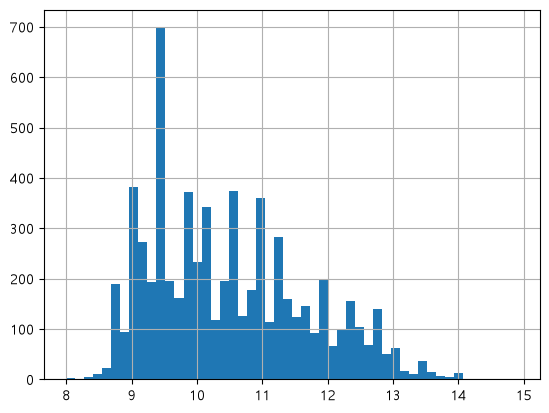

In [22]:
# 히스토그램 : 
df['alcohol'].hist(bins=50) # 최소부터 최대까지 50개의 구간으로 나누어라

<Axes: >

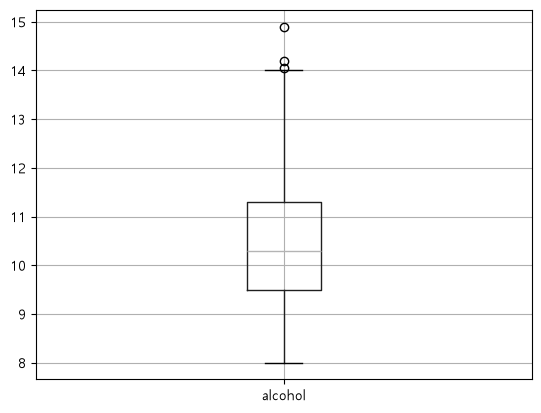

In [23]:
df.boxplot(column=['alcohol'])

<Axes: >

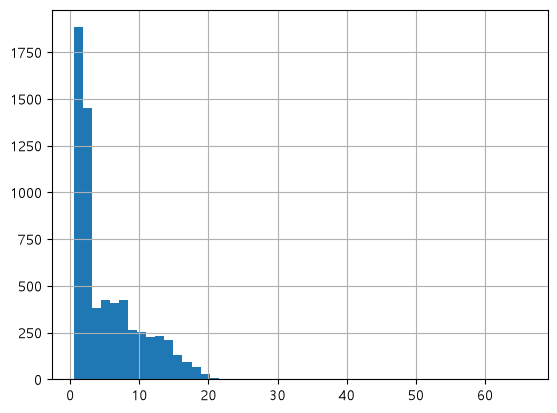

In [24]:
df['sugar'].hist(bins=50)

<Axes: >

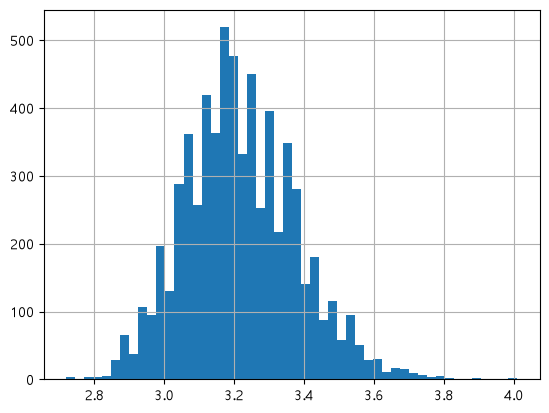

In [25]:
df['pH'].hist(bins=50)

In [28]:
df2 = df[['alcohol', 'sugar', 'pH']]

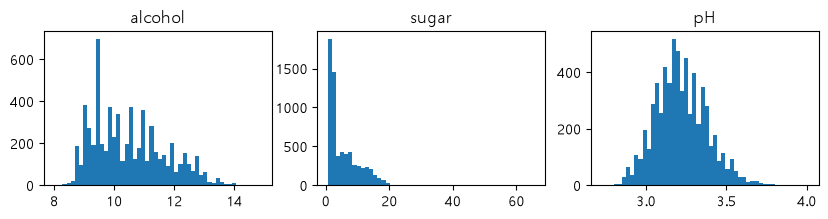

In [30]:
def plot_hist(df2):
    plt.rcParams['figure.figsize']=[10,2] # rcParams(그래프 크기 조정), 크기는 10,2
    fig = plt.figure(1) # 여러개 그래프 담을 도화지 생성
    for i in range(len(df2.columns)): # 열 수 만큼 실행
        ax = fig.add_subplot(1,3,i+1) # 전체 도화지를 1행,3열로 나누어서 i+1번째 칸을 ax라고 부른다.
        plt.hist(df2[df2.columns[i]],bins=50) # i번째 컬럼을 히스토그램으로 그려라
        ax.set_title(df2.columns[i]) # i번째 그래프 타이틀을 컬럼명으로 하겠다.
    plt.show()
plot_hist(df2)

In [31]:
data = df[df.columns[:3]].values